# 02 · Kazanma Olasılığı Modeli

**Soru:** Açık bir fırsatın önümüzdeki 120 günde kazanılma olasılığı nedir?

Bu olasılık iki iş için gerekli: (1) gelir tahmini (olasılık × tutar), (2) satış ekibinin hangi fırsata zaman
ayıracağını önceliklendirmesi. CRM'lerin varsayılan yöntemi her aşamaya sabit bir olasılık vermektir; bu notebook
ondan daha iyi ve **dürüstçe doğrulanmış** bir model kurar.

Model kodu `pipeline/analytics.py` içinde; bu notebook tasarım kararlarını gerekçeleriyle anlatır.

In [1]:
import sys
import warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="Unable to import Axes3D")
sys.path.insert(0, str(Path.cwd().parent / "pipeline"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analytics as a

plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
STAGE_TR = {"Prospecting": "Potansiyel", "Qualification": "Nitelendirme", "Proposal": "Teklif", "Negotiation": "Müzakere", "Won": "Kazanıldı", "Lost": "Kaybedildi"}

data = a.load()
con = a.connect()
print(f"{len(data.deals):,} fırsat · {len(data.history):,} aşama geçişi · analiz tarihi {data.as_of.date()}")

6,613 fırsat · 22,035 aşama geçişi · analiz tarihi 2026-10-31


## 1. Eğitim verisi: aşama içi kontrol noktaları

Tahmin, fırsatın **yaşamı boyunca herhangi bir anda** yapılabilmeli: "Teklif aşamasına yeni girmiş" fırsat ile
"Teklif aşamasında 90 gündür bekleyen" fırsat farklıdır. Bu yüzden her fırsat, ziyaret ettiği her aşamada
0, 7, 14, 30, ... günlerde birer satır üretir. Her satırdaki özellikler yalnızca o anda bilinenlerdir:
o anki aşama, aşamada geçen süre, fırsat yaşı, kanal, ürün, temsilci, bölge, sektör, şirket büyüklüğü ve
(teklif verildiyse) indirim.

In [2]:
rows = a.training_rows(data, data.as_of)
print(f"{len(rows):,} kontrol noktası · {rows['opportunity_id'].nunique():,} fırsat · pozitif oran %{rows['won'].mean()*100:.1f}")
rows[a.CATEGORICAL + a.NUMERIC + ["won"]].head()

25,128 kontrol noktası · 5,316 fırsat · pozitif oran %30.0


,stage,product,lead_source,region,sales_agent,sector,log_days_in_stage,log_age_days,discount,log_employees,won
0,Prospecting,Bulut Kurumsal,Web,Anadolu,Emre Kaya,Gıda,0.000,0.000,0.000,3.292,0
1,Qualification,Bulut Kurumsal,Web,Anadolu,Emre Kaya,Gıda,0.000,1.386,0.000,3.292,0
2,Proposal,Bulut Kurumsal,Web,Anadolu,Emre Kaya,Gıda,0.000,2.485,3.600,3.292,0
3,Prospecting,Analitik Plus,Web,Anadolu,Mustafa Koç,Enerji,0.000,0.000,0.000,3.136,0
4,Prospecting,Bulut Pro,İş Ortağı,Ege ve Akdeniz,Kaan Çelik,Holding,0.000,0.000,0.000,3.413,0


## 2. Hedef tanımı: neden "120 gün içinde kazanıldı mı"?

İlk akla gelen hedef "fırsat eninde sonunda kazanıldı mı" olur ve eğitim için yalnızca **sonuçlanmış** fırsatlar
kullanılır. Bu yaklaşım **sansürleme yanlılığı** yaratır: CRM'de unutulmuş, hiç kapatılmayan fırsatlar eğitim verisine
hiç girmez. Model "aylardır aynı aşamada bekleyen fırsat neredeyse hiç kazanılmaz" bilgisini öğrenemez.

Çözüm: hedefi sabit bir ufukla tanımlamak. Penceresi tamamen gözlenmiş her kontrol noktası etiketlenebilir; açık kalan
fırsatlar da "120 günde kazanılmadı" olarak eğitime girer. Ayrıca hedef, tahminin hedefiyle (önümüzdeki 120 günün geliri)
birebir aynı olur.

İki yaklaşımı takılmış fırsatlar üzerinde karşılaştıralım:

In [3]:
# (a) Yanlış yaklaşım: yalnızca sonuçlanmış fırsatlar, hedef = eninde sonunda kazanıldı mı
resolved_ids = set(data.deals.loc[data.deals["resolved"], "opportunity_id"])
naive_rows = rows[rows["opportunity_id"].isin(resolved_ids)].copy()
naive_rows["won_eventually"] = naive_rows["opportunity_id"].map(data.deals.set_index("opportunity_id")["won"])
naive_model = a.build_model().fit(naive_rows[a.CATEGORICAL + a.NUMERIC], naive_rows["won_eventually"])

# (b) Doğru yaklaşım: tüm kontrol noktaları, hedef = 120 gün içinde kazanıldı mı
horizon_model = a.build_model().fit(rows[a.CATEGORICAL + a.NUMERIC], rows["won"])

open_now = a.snapshot(data, data.as_of)
durations = a.run_sql(con, "03_asama_sureleri.sql").set_index("stage")["p90_days"]
open_now["stalled"] = np.expm1(open_now["log_days_in_stage"]).round() > open_now["stage"].map(durations)
open_now["p_naive"] = naive_model.predict_proba(open_now[a.CATEGORICAL + a.NUMERIC])[:, 1]
open_now["p_horizon"] = horizon_model.predict_proba(open_now[a.CATEGORICAL + a.NUMERIC])[:, 1]
open_now.groupby("stalled")[["p_naive", "p_horizon"]].mean().rename(index={False: "Aktif", True: "Takılmış"})

,p_naive,p_horizon
stalled,,
Aktif,0.301,0.241
Takılmış,0.195,0.083


Sansürlenmiş yaklaşım takılmış fırsatlara ufuk tabanlı modelin iki katından fazla olasılık veriyor; çünkü eğitimde hiç
bitmeyen bir fırsat görmedi. Ufuk tabanlı hedef bu fırsatları doğru şekilde düşük puanlıyor. (Sansürlenmiş modelin hedefi
"eninde sonunda" kazanılma olduğu için aktif fırsatlarda da biraz yüksek olması beklenir; asıl fark takılmış fırsatlarda.)

## 3. Özellik seçimi: çoklu doğrusallık kararı

İlk sürümde "indirim verildi mi" (`has_discount`) bayrağı da vardı. İndirim yalnızca Teklif aşamasında belirlendiği için
bu bayrak neredeyse tamamen "aşama Teklif veya Müzakere mi" bilgisiyle aynıdır:

In [4]:
late_stage = rows["stage"].isin(["Proposal", "Negotiation"])
has_discount = rows["discount"] > 0
print(f"'İndirim var' bayrağı ile 'geç aşama' bilgisinin aynı olduğu satırların payı: %{(has_discount == late_stage).mean() * 100:.1f}")

'İndirim var' bayrağı ile 'geç aşama' bilgisinin aynı olduğu satırların payı: %93.7


Bayrakla ve bayraksız iki modeli aynı zamana göre ayrılmış test üzerinde karşılaştıralım:

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cutoff = pd.Timestamp("2026-03-01")
train = a.training_rows(data, cutoff)
test = rows[rows["at"] > cutoff - pd.Timedelta(days=a.HORIZON_DAYS)]
for frame in (train, test):
    frame["has_discount"] = (frame["discount"] > 0).astype(float)

def variant(numeric):
    pre = ColumnTransformer([("categorical", OneHotEncoder(handle_unknown="ignore"), a.CATEGORICAL), ("numeric", StandardScaler(), numeric)])
    model = Pipeline([("pre", pre), ("model", LogisticRegression(C=0.5, max_iter=2000))]).fit(train[a.CATEGORICAL + numeric], train["won"])
    names = model.named_steps["pre"].get_feature_names_out()
    stage = {n.split("stage_")[1]: c for n, c in zip(names, model.named_steps["model"].coef_[0]) if "__stage_" in n}
    return {"AUC": roc_auc_score(test["won"], model.predict_proba(test[a.CATEGORICAL + numeric])[:, 1]), **{STAGE_TR[k]: v for k, v in stage.items()}}

pd.DataFrame({"Bayraklı": variant(a.NUMERIC + ["has_discount"]), "Bayraksız (seçilen)": variant(a.NUMERIC)}).T.round(3)

C:\Users\USER\AppData\Local\Temp\ipykernel_11972\3771446809.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frame["has_discount"] = (frame["discount"] > 0).astype(float)


,AUC,Müzakere,Teklif,Potansiyel,Nitelendirme
Bayraklı,0.749,0.868,-0.103,-1.027,-0.142
Bayraksız (seçilen),0.747,1.018,0.037,-1.158,-0.280


Bayrak eklendiğinde ayırt etme gücü neredeyse hiç artmıyor; buna karşın geç aşamaların etkisinin bir kısmı bayrağa kayıyor
ve Teklif ile Nitelendirme katsayıları birbirine yaklaşıyor. Bu, çoklu doğrusallığın tipik belirtisi: iki değişken aynı bilgiyi
taşıdığında model etkiyi aralarında keyfi biçimde paylaştırır ve katsayılar veri değiştikçe kararsızlaşır (bu projenin daha önceki
bir veri üretiminde Teklif katsayısı Nitelendirme'nin altına bile düşmüştü). Yorumlanabilir ve kararlı bir model için bayrak
çıkarıldı; indirimin büyüklüğü (`discount`) modelde kalıyor.

## 4. Zamana göre doğrulama

Rastgele bölme burada yanlış olurdu: aynı fırsatın kontrol noktaları hem eğitime hem teste düşer ve gelecekteki
bilgi geçmişe sızar. Bunun yerine **zamana göre bölme**: 1 Mart 2026'ya kadar bilinen veriyle eğitim, sonrasında
gözlenen kontrol noktalarında test.

In [6]:
from sklearn.metrics import roc_auc_score, brier_score_loss
cutoff = pd.Timestamp("2026-03-01")
train = a.training_rows(data, cutoff)
test = rows[rows["at"] > cutoff - pd.Timedelta(days=a.HORIZON_DAYS)]
test = test[~test.set_index(["opportunity_id", "at"]).index.isin(train.set_index(["opportunity_id", "at"]).index)]
model = a.build_model().fit(train[a.CATEGORICAL + a.NUMERIC], train["won"])
p_model = model.predict_proba(test[a.CATEGORICAL + a.NUMERIC])[:, 1]
p_stage = test["stage"].map(train.groupby("stage")["won"].mean())
pd.DataFrame({
    "ROC AUC": [roc_auc_score(test["won"], p_model), roc_auc_score(test["won"], p_stage)],
    "Brier": [brier_score_loss(test["won"], p_model), brier_score_loss(test["won"], p_stage)],
}, index=["Lojistik regresyon", "Aşama oranı (CRM standardı)"])

,ROC AUC,Brier
Lojistik regresyon,0.747,0.175
Aşama oranı (CRM standardı),0.668,0.191


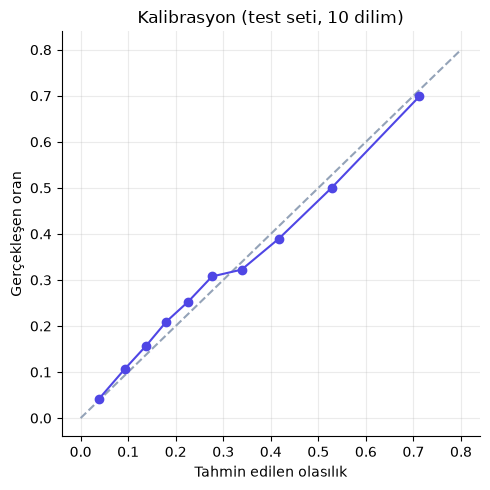

In [7]:
bins = pd.qcut(p_model, 10, labels=False, duplicates="drop")
cal = pd.DataFrame({"bin": bins, "p": p_model, "y": test["won"].values}).groupby("bin").mean()
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, .8], [0, .8], "--", color="#94a3b8"); ax.plot(cal["p"], cal["y"], "o-", color="#4f46e5")
ax.set_xlabel("Tahmin edilen olasılık"); ax.set_ylabel("Gerçekleşen oran"); ax.set_title("Kalibrasyon (test seti, 10 dilim)")
plt.tight_layout()

Model hem ayırt etmede (AUC) hem olasılık doğruluğunda (Brier) aşama oranından iyi ve iyi kalibre: "%30" dediği
fırsatların gerçekten yaklaşık %30'u kazanılıyor. Kalibrasyon önemli; çünkü olasılıklar gelire çevrilecek.

## 5. Model neyi öğrendi?

In [8]:
odds = a.odds_ratios(horizon_model)
show = odds[odds["group"].isin(["stage", "lead_source"]) | (odds["level"] == "")].copy()
show["label"] = np.where(show["level"] == "", show["group"], show["group"] + ": " + show["level"].replace(STAGE_TR))
show.sort_values("odds_ratio")[["label", "coef", "odds_ratio"]]

,label,coef,odds_ratio
2,stage: Potansiyel,-1.215,0.297
13,lead_source: Outbound,-0.399,0.671
3,stage: Nitelendirme,-0.337,0.714
61,log_age_days,-0.324,0.724
12,lead_source: Etkinlik,-0.304,0.738
60,log_days_in_stage,-0.298,0.742
11,lead_source: Bilinmiyor,-0.201,0.818
63,log_employees,-0.062,0.940
15,lead_source: Web,-0.008,0.992
1,stage: Teklif,0.030,1.030


- Aşamalar huni sırasıyla artıyor (Müzakere en yüksek): beklenen ve yorumlanabilir.
- **Aşamada geçen süre ve fırsat yaşı** kazanma şansını belirgin şekilde düşürüyor: takılmış fırsatları ayırt eden bu iki değişken.
- Referans ve İş Ortağı kanalları Web'e göre daha yüksek, Outbound daha düşük olasılık taşıyor.
- Sayısal özellikler standartlaştırıldığı için odds oranı "1 standart sapma artış"ın etkisidir.

## Sınırlamalar

- Doğrusal model: indirimin azalan getirisi gibi doğrusal olmayan ilişkileri tam yakalayamaz (bkz. notebook 01, indirim analizi).
  Bir sonraki adım olarak spline özellikleri veya gradient boosting denenebilir; ama yorumlanabilirlik kaybı tartılmalı.
- Temsilci etkileri doğrudan modelde: yeni bir temsilci için model ortalamaya döner.
- Kontrol noktaları aynı fırsattan birden çok satır üretir; bu yüzden standart hatalar (katsayıların güven aralıkları)
  olduğundan dar görünür. Tahmin için sorun değil, ama katsayı yorumunda dikkat edilmeli.